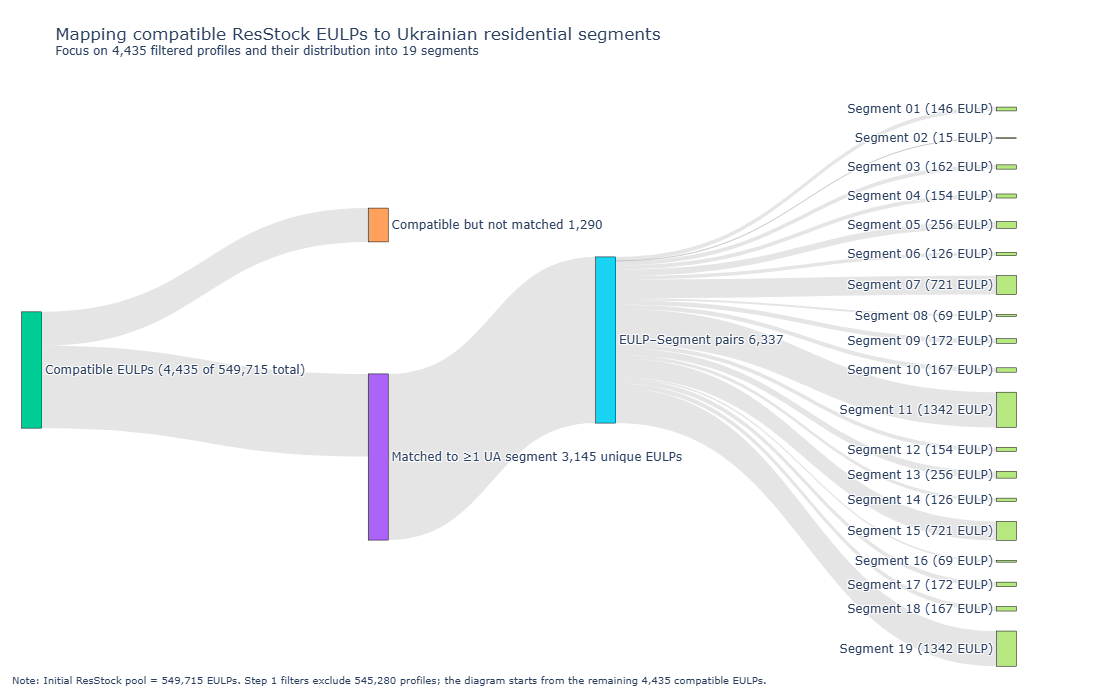

In [32]:
import plotly.graph_objects as go

# ---------------------------
# 1. Core aggregate numbers
# ---------------------------
ua_compatible    = 4_435
matched_eulp     = 3_145
unmatched_eulp   = ua_compatible - matched_eulp  # 1,290
pairs_total      = 6_337

# -------------------------------------------
# 2. Ukrainian segments: labels + pair counts
# -------------------------------------------

ua_segment_labels = [
    "Segment 01",
    "Segment 02",
    "Segment 03",
    "Segment 04",
    "Segment 05",
    "Segment 06",
    "Segment 07",
    "Segment 08",
    "Segment 09",
    "Segment 10",
    "Segment 11",
    "Segment 12",
    "Segment 13",
    "Segment 14",
    "Segment 15",
    "Segment 16",
    "Segment 17",
    "Segment 18",
    "Segment 19",
]

ua_segment_pair_counts = [
    146, 15, 162, 154, 256,
    126, 721, 69, 172, 167,
    1342, 154, 256, 126, 721,
    69, 172, 167, 1342
]

assert len(ua_segment_labels) == 19
assert len(ua_segment_pair_counts) == 19
assert sum(ua_segment_pair_counts) == pairs_total

# ---------------------------
# 3. Nodes
# ---------------------------

segment_node_labels = [
    f"{lbl}\n({val} EULP)"
    for lbl, val in zip(ua_segment_labels, ua_segment_pair_counts)
]

node_labels = [
    "Сompatible EULPs\n(4,435 of 549,715 total)",   # 0
    "Matched to ≥1 UA segment\n3,145 unique EULPs",  # 1
    "Сompatible but not matched\n1,290",             # 2
    "EULP–Segment pairs\n6,337"                     # 3
] + segment_node_labels                              # 4–22

node_customdata = [
    (
        "Subset of ResStock EULPs that passes Step 1 filters:\n"
        "- ASHRAE climate zone 5A\n"
        "- Non-ducted room AC\n"
        "- Non-vacant dwellings\n"
        "- Non-mobile / non-wood-frame\n"
        "- No ceiling fan usage\n"
        "Count: 4,435 out of 549,715 total."
    ),
    (
        "Unique EULPs that match at least one Ukrainian segment\n"
        "by building type, bedrooms, heating fuel,\n"
        "annual consumption band and appliance indicators.\n"
        "Count: 3,145"
    ),
    (
        "Сompatible EULPs that do not fit any of the\n"
        "19 Ukrainian residential segments.\n"
        "Count: 1,290"
    ),
    (
        "One-to-many expansion:\n"
        "3,145 unique EULPs → 6,337 EULP–Segment pairs.\n"
        "Each pair links one EULP to one UA segment."
    ),
] + [
    f"Ukrainian residential segment: {lbl}\n"
    f"EULP–Segment pairs assigned: {val:,d}"
    for lbl, val in zip(ua_segment_labels, ua_segment_pair_counts)
]

node_colors = [
    "#00CC96",  # compatible
    "#AB63FA",  # matched
    "#FFA15A",  # not matched
    "#19D3F3",  # EULP–Segment pairs
] + ["#B6E880"] * 19

# ---------------------------
# 3a. Node positions (x, y) – stretched horizontally
# ---------------------------
n_segments = len(ua_segment_labels)

# previously: [0.05, 0.30, 0.30, 0.55] + [0.80]*n_segments
node_x = [
    0.02,  # 0 Сompatible – almost at the left edge
    0.34,  # 1 Matched
    0.34,  # 2 Not matched
    0.55,  # 3 EULP–Segment pairs
] + [0.92] * n_segments  # segments closer to the right edge, with space for labels

step = 1.0 / (n_segments + 1)
segment_y = [(i + 1) * step for i in range(n_segments)]

node_y = [
    0.5,   # Сompatible
    0.65,  # Matched
    0.25,  # Not matched
    0.45,  # EULP–Segment pairs
] + segment_y

# ---------------------------
# 4. Links
# ---------------------------

link_sources = []
link_targets = []
link_values  = []
link_customdata = []

# 0 -> 1, 0 -> 2
link_sources += [0, 0]
link_targets += [1, 2]
link_values  += [matched_eulp, unmatched_eulp]
link_customdata += [
    "Сompatible EULPs that match ≥1 Ukrainian segment.",
    "Сompatible EULPs that do not match any Ukrainian segment.",
]

# 1 -> 3
link_sources.append(1)
link_targets.append(3)
link_values.append(pairs_total)
link_customdata.append(
    "One-to-many expansion:\n"
    "3,145 unique EULPs → 6,337 EULP–Segment pairs."
)

# 3 -> segments
for i, (lbl, val) in enumerate(zip(ua_segment_labels, ua_segment_pair_counts)):
    link_sources.append(3)
    link_targets.append(4 + i)
    link_values.append(val)
    link_customdata.append(
        f"EULP–Segment pairs assigned to {lbl}.\n"
        f"Count: {val:,d}"
    )

link_colors = ["rgba(150,150,150,0.25)"] * len(link_values)

# ---------------------------
# 5. Build Sankey diagram
# ---------------------------

fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=20,
                thickness=20,
                line=dict(color="black", width=0.5),
                label=node_labels,
                color=node_colors,
                customdata=node_customdata,
                hovertemplate="%{customdata}<extra></extra>",
                x=node_x,
                y=node_y,
            ),
            link=dict(
                source=link_sources,
                target=link_targets,
                value=link_values,
                color=link_colors,
                customdata=link_customdata,
                hovertemplate="%{customdata}<br>"
                              "Count: %{value:,.0f}<extra></extra>",
            ),
        )
    ]
)

fig.update_layout(
    title_text=(
        "Mapping compatible ResStock EULPs to Ukrainian residential segments<br>"
        "<sup>Focus on 4,435 filtered profiles and their distribution into 19 segments</sup>"
    ),
    font=dict(size=12),
    width=1100,
    height=700,
    margin=dict(l=10, r=10, t=80, b=40),
)

fig.add_annotation(
    x=0.0,
    y=-0.05,
    xref="paper",
    yref="paper",
    showarrow=False,
    align="left",
    text=(
        "Note: Initial ResStock pool = 549,715 EULPs. "
        "Step 1 filters exclude 545,280 profiles; "
        "the diagram starts from the remaining 4,435 сompatible EULPs."
    ),
    font=dict(size=10),
)

fig.show()


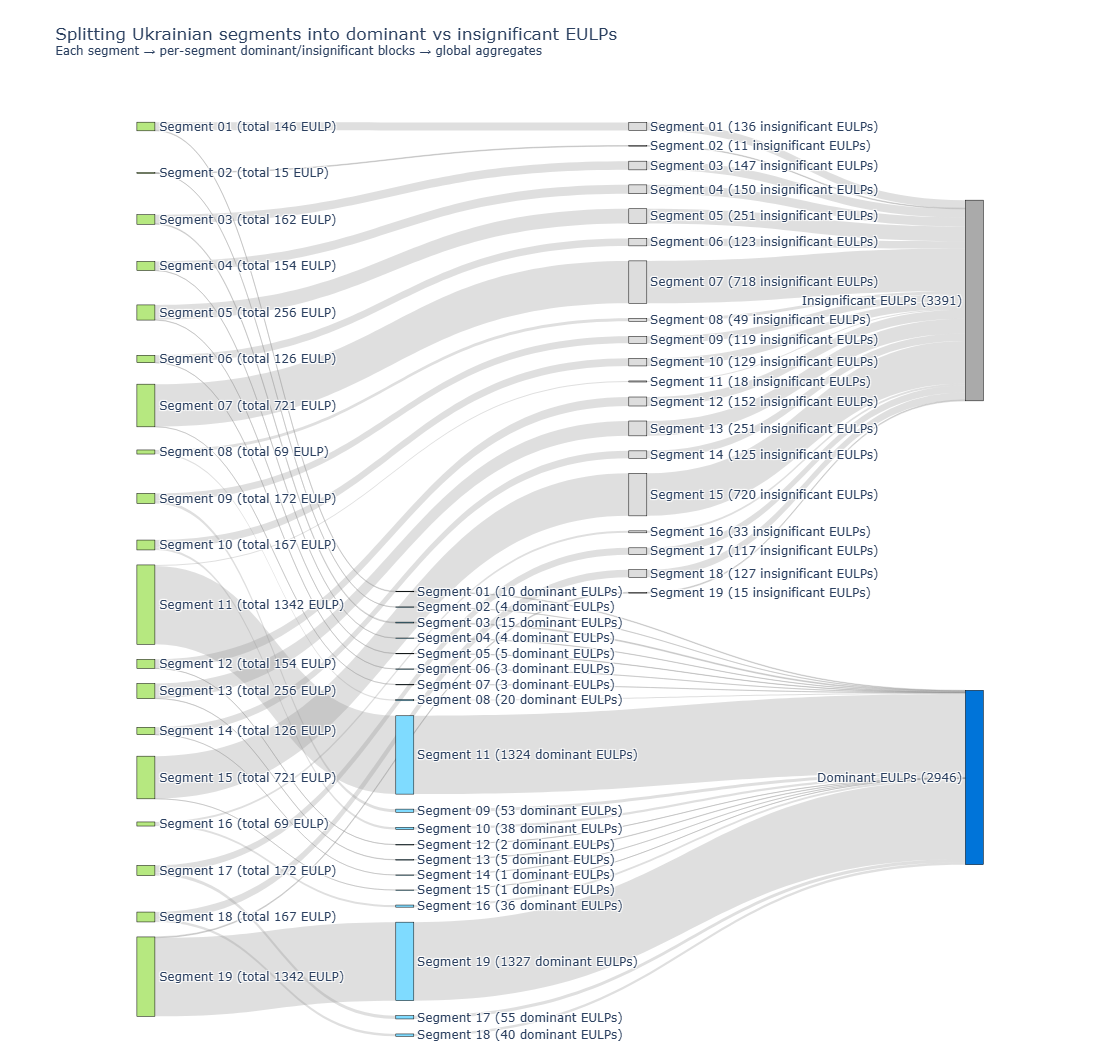

In [4]:
import plotly.graph_objects as go

# -------------------------------------------
# 1. Ukrainian segments and EULP statistics
# -------------------------------------------

ua_segment_labels = [
    "Segment 01",
    "Segment 02",
    "Segment 03",
    "Segment 04",
    "Segment 05",
    "Segment 06",
    "Segment 07",
    "Segment 08",
    "Segment 09",
    "Segment 10",
    "Segment 11",
    "Segment 12",
    "Segment 13",
    "Segment 14",
    "Segment 15",
    "Segment 16",
    "Segment 17",
    "Segment 18",
    "Segment 19",
]

# Total linked EULP per segment (from first Sankey)
total_eulp_counts = [
    146, 15, 162, 154, 256,
    126, 721, 69, 172, 167,
    1342, 154, 256, 126, 721,
    69, 172, 167, 1342
]

# EULP with non-zero / dominant weights per segment
nonzero_eulp_counts = [
    10, 4, 15, 4, 5,
    3, 3, 20, 53, 38,
    1324, 2, 5, 1, 1,
    36, 55, 40, 1327
]

assert len(ua_segment_labels) == 19
assert len(total_eulp_counts) == 19
assert len(nonzero_eulp_counts) == 19

# EULP with zero / insignificant weights per segment
zero_eulp_counts = [
    total - nz for total, nz in zip(total_eulp_counts, nonzero_eulp_counts)
]

total_nonzero = sum(nonzero_eulp_counts)  # dominant EULPs
total_zero    = sum(zero_eulp_counts)     # insignificant EULPs
total_all     = sum(total_eulp_counts)    # 6,337 EULP

# ---------------------------
# 2. Nodes
# ---------------------------

n_segments = len(ua_segment_labels)

# 0..18 – segment nodes (left)
segment_node_labels = [
    f"{lbl}\n(total {cnt} EULP)"
    for lbl, cnt in zip(ua_segment_labels, total_eulp_counts)
]

# 19..37 – per-segment dominant (non-zero) nodes (middle, bottom group)
segment_nonzero_labels = [
    f"{lbl}\n({cnt} dominant EULPs)"
    for lbl, cnt in zip(ua_segment_labels, nonzero_eulp_counts)
]

# 38..56 – per-segment insignificant (zero / near-zero) nodes (middle, top group)
segment_zero_labels = [
    f"{lbl}\n({cnt} insignificant EULPs)"
    for lbl, cnt in zip(ua_segment_labels, zero_eulp_counts)
]

# 57..58 – aggregate nodes on the right
# 57 – bottom (dominant), 58 – top (insignificant)
aggregate_labels = [
    f"Dominant EULPs\n({total_nonzero})",       # 57 – bottom
    f"Insignificant EULPs\n({total_zero})",     # 58 – top
]

node_labels = (
    segment_node_labels +
    segment_nonzero_labels +
    segment_zero_labels +
    aggregate_labels
)

# customdata for hover
node_customdata = []

# Left segment nodes
for lbl, total, nz, z in zip(
    ua_segment_labels, total_eulp_counts,
    nonzero_eulp_counts, zero_eulp_counts
):
    node_customdata.append(
        f"{lbl}\n"
        f"Total linked EULP: {total:,d}\n"
        f"Dominant EULPs (non-zero / high weight): {nz:,d}\n"
        f"Insignificant EULPs (zero / near-zero weight): {z:,d}"
    )

# Middle dominant nodes
for lbl, nz in zip(ua_segment_labels, nonzero_eulp_counts):
    node_customdata.append(
        f"{lbl} – dominant EULPs\n"
        f"Non-zero / high-weight profiles that form ~98% of the segment mass\n"
        f"Count: {nz:,d}"
    )

# Middle insignificant nodes
for lbl, z in zip(ua_segment_labels, zero_eulp_counts):
    node_customdata.append(
        f"{lbl} – insignificant EULPs\n"
        f"Zero or near-zero weight profiles (~2% of the segment mass)\n"
        f"Count: {z:,d}"
    )

# Aggregate nodes
node_customdata.append(
    "Dominant EULPs across all segments\n"
    f"Total: {total_nonzero:,d} out of {total_all:,d} linked EULPs"
)
node_customdata.append(
    "Insignificant EULPs across all segments\n"
    f"Total: {total_zero:,d} out of {total_all:,d} linked EULPs"
)

# Colors
node_colors = (
    ["#B6E880"] * n_segments +       # left segments
    ["#7FDBFF"] * n_segments +       # middle dominant (bottom group)
    ["#DDDDDD"] * n_segments +       # middle insignificant (top group)
    ["#0074D9", "#AAAAAA"]           # right aggregates
)

# ---------------------------
# 3. Node positions (x, y)
# ---------------------------

# X-positions
segment_x = 0.03   # left column
nonzero_x = 0.33   # middle bottom
zero_x    = 0.60   # middle top
agg_x     = 0.99   # right column

# Left column: segments spread from top to bottom
step_left = 1.0 / (n_segments + 1)
segment_y_left = [(i + 1) * step_left for i in range(n_segments)]

# Middle top group: insignificant EULP (upper band ~0.05–0.40)
zero_start, zero_end = 0.05, 0.40
zero_step = (zero_end - zero_start) / (n_segments - 1)
zero_y_mid = [zero_start + i * zero_step for i in range(n_segments)]

# Middle bottom group: dominant EULP (lower band ~0.55–0.85)
nz_start, nz_end = 0.55, 0.85
nz_step = (nz_end - nz_start) / (n_segments - 1)
nonzero_y_mid = [nz_start + i * nz_step for i in range(n_segments)]

node_x = []
node_y = []

# segments (0..18)
for y in segment_y_left:
    node_x.append(segment_x)
    node_y.append(y)

# per-segment dominant nodes (19..37) – bottom group
for y in nonzero_y_mid:
    node_x.append(nonzero_x)
    node_y.append(y)

# per-segment insignificant nodes (38..56) – top group
for y in zero_y_mid:
    node_x.append(zero_x)
    node_y.append(y)

# aggregate nodes (57..58): dominant bottom, insignificant top
node_x += [agg_x, agg_x]
node_y += [0.75, 0.25]

# ---------------------------
# 4. Links
# ---------------------------

link_sources = []
link_targets = []
link_values  = []
link_custom  = []

nonzero_agg_idx = 3 * n_segments      # 57
zero_agg_idx    = 3 * n_segments + 1  # 58

for i, (lbl, nz, z) in enumerate(
    zip(ua_segment_labels, nonzero_eulp_counts, zero_eulp_counts)
):
    seg_idx = i
    nz_idx  = n_segments + i          # 19..37
    z_idx   = 2 * n_segments + i      # 38..56

    # Segment -> its dominant node (bottom middle)
    link_sources.append(seg_idx)
    link_targets.append(nz_idx)
    link_values.append(nz)
    link_custom.append(f"{lbl}: {nz:,d} dominant EULPs")

    # Segment -> its insignificant node (top middle)
    link_sources.append(seg_idx)
    link_targets.append(z_idx)
    link_values.append(z)
    link_custom.append(f"{lbl}: {z:,d} insignificant EULPs")

    # Dominant node -> aggregate dominant (bottom right)
    link_sources.append(nz_idx)
    link_targets.append(nonzero_agg_idx)
    link_values.append(nz)
    link_custom.append(f"{lbl} dominant EULPs flowing to aggregate node")

    # Insignificant node -> aggregate insignificant (top right)
    link_sources.append(z_idx)
    link_targets.append(zero_agg_idx)
    link_values.append(z)
    link_custom.append(f"{lbl} insignificant EULPs flowing to aggregate node")

link_colors = ["rgba(150,150,150,0.30)"] * len(link_values)

# ---------------------------
# 5. Build Sankey
# ---------------------------

fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=15,
                thickness=18,
                line=dict(color="black", width=0.5),
                label=node_labels,
                color=node_colors,
                customdata=node_customdata,
                hovertemplate="%{customdata}<extra></extra>",
                x=node_x,
                y=node_y,
            ),
            link=dict(
                source=link_sources,
                target=link_targets,
                value=link_values,
                color=link_colors,
                customdata=link_custom,
                hovertemplate="%{customdata}<br>"
                              "EULP count: %{value:,.0f}<extra></extra>",
            ),
        )
    ]
)

fig.update_layout(
    title_text=(
        "Splitting Ukrainian segments into dominant vs insignificant EULPs<br>"
        "<sup>Each segment → per-segment dominant/insignificant blocks → global aggregates</sup>"
    ),
    font=dict(size=12),
    width=1150,
    height=1050,
    margin=dict(l=120, r=120, t=80, b=40),
)

fig.show()


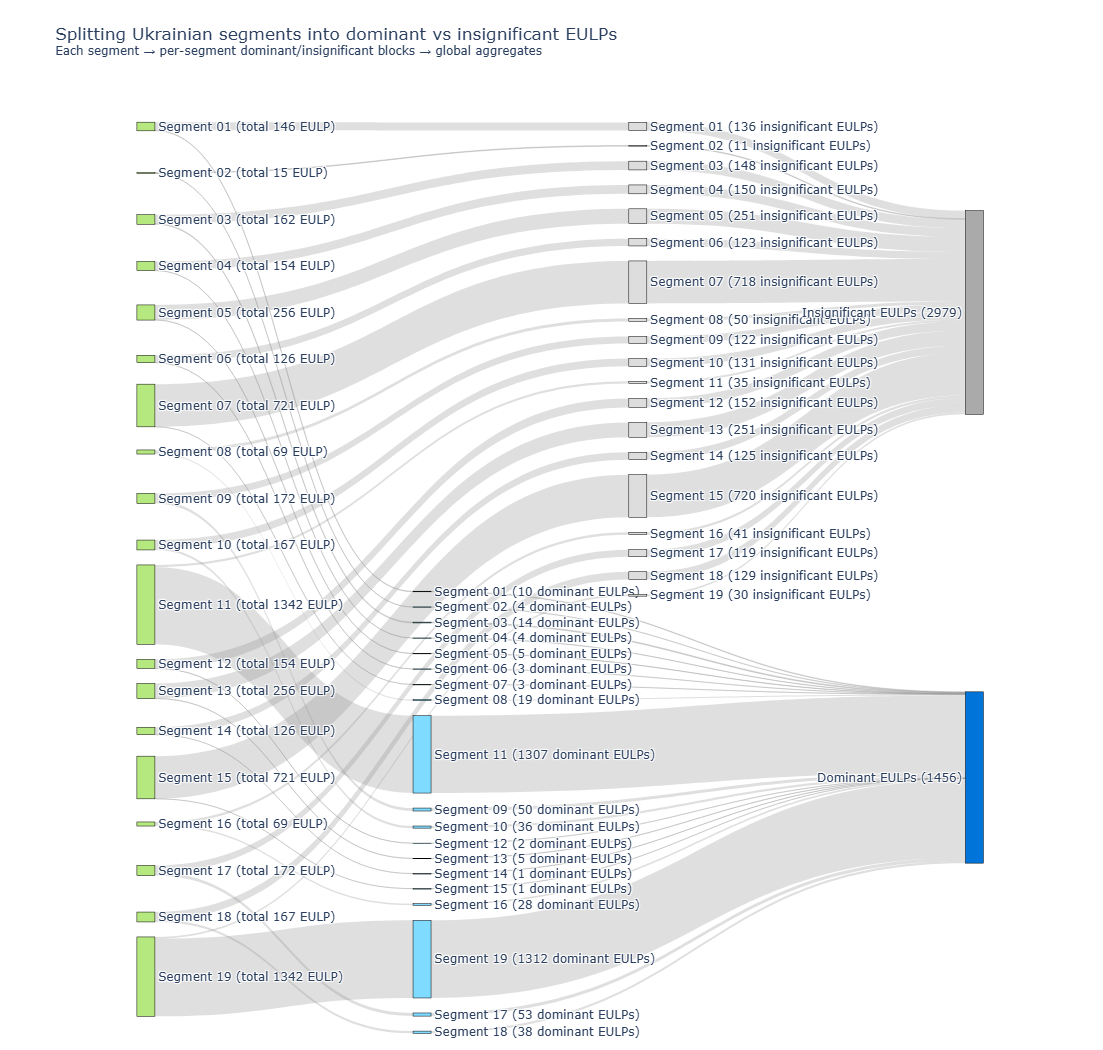

In [6]:
import plotly.graph_objects as go

# -------------------------------------------
# 1. Ukrainian segments and EULP statistics
# -------------------------------------------

ua_segment_labels = [
    "Segment 01",
    "Segment 02",
    "Segment 03",
    "Segment 04",
    "Segment 05",
    "Segment 06",
    "Segment 07",
    "Segment 08",
    "Segment 09",
    "Segment 10",
    "Segment 11",
    "Segment 12",
    "Segment 13",
    "Segment 14",
    "Segment 15",
    "Segment 16",
    "Segment 17",
    "Segment 18",
    "Segment 19",
]

# Left column: total EULP per segment
total_eulp_counts = [
    146, 15, 162, 154, 256,
    126, 721, 69, 172, 167,
    1342, 154, 256, 126, 721,
    69, 172, 167, 1342
]

# Middle top column: insignificant EULPs
zero_eulp_counts = [
    136, 11, 148, 150, 251,
    123, 718, 50, 122, 131,
    35, 152, 251, 125, 720,
    41, 119, 129, 30
]

# Middle bottom column: dominant EULPs
nonzero_eulp_counts = [
    10, 4, 14, 4, 5,
    3, 3, 19, 50, 36,
    1307, 2, 5, 1, 1,
    28, 53, 38, 1312
]

assert len(ua_segment_labels) == 19
assert len(total_eulp_counts) == 19
assert len(zero_eulp_counts) == 19
assert len(nonzero_eulp_counts) == 19

# Optional consistency check
for seg, total, z, nz in zip(ua_segment_labels, total_eulp_counts, zero_eulp_counts, nonzero_eulp_counts):
    assert total == z + nz, f"{seg}: total != insignificant + dominant"

# Real sums used by Sankey flow thickness
real_total_zero = sum(zero_eulp_counts)        # 3442
real_total_nonzero = sum(nonzero_eulp_counts)  # 2895
real_total_all = sum(total_eulp_counts)        # 6337

# Displayed totals on the right (hardcoded text only)
display_total_zero = 2979
display_total_nonzero = 1456

# ---------------------------
# 2. Nodes
# ---------------------------

n_segments = len(ua_segment_labels)

# 0..18 – left segment nodes
segment_node_labels = [
    f"{lbl}\n(total {cnt} EULP)"
    for lbl, cnt in zip(ua_segment_labels, total_eulp_counts)
]

# 19..37 – middle bottom dominant nodes
segment_nonzero_labels = [
    f"{lbl}\n({cnt} dominant EULPs)"
    for lbl, cnt in zip(ua_segment_labels, nonzero_eulp_counts)
]

# 38..56 – middle top insignificant nodes
segment_zero_labels = [
    f"{lbl}\n({cnt} insignificant EULPs)"
    for lbl, cnt in zip(ua_segment_labels, zero_eulp_counts)
]

# 57..58 – right aggregate nodes
# Labels are hardcoded as requested
aggregate_labels = [
    f"Dominant EULPs\n({display_total_nonzero})",      # 57 – bottom
    f"Insignificant EULPs\n({display_total_zero})",    # 58 – top
]

node_labels = (
    segment_node_labels +
    segment_nonzero_labels +
    segment_zero_labels +
    aggregate_labels
)

node_customdata = []

# Left nodes
for lbl, total, nz, z in zip(
    ua_segment_labels, total_eulp_counts,
    nonzero_eulp_counts, zero_eulp_counts
):
    node_customdata.append(
        f"{lbl}\n"
        f"Total EULP: {total:,d}\n"
        f"Dominant EULPs: {nz:,d}\n"
        f"Insignificant EULPs: {z:,d}"
    )

# Middle dominant nodes
for lbl, nz in zip(ua_segment_labels, nonzero_eulp_counts):
    node_customdata.append(
        f"{lbl} – dominant EULPs\n"
        f"Count: {nz:,d}"
    )

# Middle insignificant nodes
for lbl, z in zip(ua_segment_labels, zero_eulp_counts):
    node_customdata.append(
        f"{lbl} – insignificant EULPs\n"
        f"Count: {z:,d}"
    )

# Right aggregate nodes
# Hover text also hardcoded as requested
node_customdata.append(
    "Dominant EULPs across all segments\n"
    f"Reported total: {display_total_nonzero}"
)
node_customdata.append(
    "Insignificant EULPs across all segments\n"
    f"Reported total: {display_total_zero}"
)

# Colors
node_colors = (
    ["#B6E880"] * n_segments +   # left segments
    ["#7FDBFF"] * n_segments +   # middle dominant
    ["#DDDDDD"] * n_segments +   # middle insignificant
    ["#0074D9", "#AAAAAA"]       # right aggregates
)

# ---------------------------
# 3. Node positions (x, y)
# ---------------------------

segment_x = 0.03
nonzero_x = 0.35   # dominant bottom
zero_x    = 0.60   # insignificant top
agg_x     = 0.99

# Left column
step_left = 1.0 / (n_segments + 1)
segment_y_left = [(i + 1) * step_left for i in range(n_segments)]

# Top middle group: insignificant
zero_start, zero_end = 0.05, 0.40
zero_step = (zero_end - zero_start) / (n_segments - 1)
zero_y_mid = [zero_start + i * zero_step for i in range(n_segments)]

# Bottom middle group: dominant
nz_start, nz_end = 0.55, 0.85
nz_step = (nz_end - nz_start) / (n_segments - 1)
nonzero_y_mid = [nz_start + i * nz_step for i in range(n_segments)]

node_x = []
node_y = []

# Left nodes
for y in segment_y_left:
    node_x.append(segment_x)
    node_y.append(y)

# Middle dominant nodes
for y in nonzero_y_mid:
    node_x.append(nonzero_x)
    node_y.append(y)

# Middle insignificant nodes
for y in zero_y_mid:
    node_x.append(zero_x)
    node_y.append(y)

# Right aggregate nodes
node_x += [agg_x, agg_x]
node_y += [0.75, 0.25]  # dominant bottom, insignificant top

# ---------------------------
# 4. Links
# ---------------------------

link_sources = []
link_targets = []
link_values  = []
link_custom  = []

nonzero_agg_idx = 3 * n_segments      # 57
zero_agg_idx    = 3 * n_segments + 1  # 58

for i, (lbl, nz, z) in enumerate(
    zip(ua_segment_labels, nonzero_eulp_counts, zero_eulp_counts)
):
    seg_idx = i
    nz_idx  = n_segments + i          # 19..37
    z_idx   = 2 * n_segments + i      # 38..56

    # Segment -> dominant
    link_sources.append(seg_idx)
    link_targets.append(nz_idx)
    link_values.append(nz)
    link_custom.append(f"{lbl}: {nz:,d} dominant EULPs")

    # Segment -> insignificant
    link_sources.append(seg_idx)
    link_targets.append(z_idx)
    link_values.append(z)
    link_custom.append(f"{lbl}: {z:,d} insignificant EULPs")

    # Dominant -> aggregate dominant
    link_sources.append(nz_idx)
    link_targets.append(nonzero_agg_idx)
    link_values.append(nz)
    link_custom.append(f"{lbl} dominant EULPs flowing to aggregate node")

    # Insignificant -> aggregate insignificant
    link_sources.append(z_idx)
    link_targets.append(zero_agg_idx)
    link_values.append(z)
    link_custom.append(f"{lbl} insignificant EULPs flowing to aggregate node")

link_colors = ["rgba(150,150,150,0.30)"] * len(link_values)

# ---------------------------
# 5. Build Sankey
# ---------------------------

fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=15,
                thickness=18,
                line=dict(color="black", width=0.5),
                label=node_labels,
                color=node_colors,
                customdata=node_customdata,
                hovertemplate="%{customdata}<extra></extra>",
                x=node_x,
                y=node_y,
            ),
            link=dict(
                source=link_sources,
                target=link_targets,
                value=link_values,
                color=link_colors,
                customdata=link_custom,
                hovertemplate="%{customdata}<br>EULP count: %{value:,.0f}<extra></extra>",
            ),
        )
    ]
)

fig.update_layout(
    title_text=(
        "Splitting Ukrainian segments into dominant vs insignificant EULPs<br>"
        "<sup>Each segment → per-segment dominant/insignificant blocks → global aggregates</sup>"
    ),
    font=dict(size=12),
    width=1150,
    height=1050,
    margin=dict(l=120, r=120, t=80, b=40),
)

fig.show()